# Discontinuities from normal fields: two complete author examples


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`vase_normals`，shape `(1, 168, 168, 3)`，dtype `<f8`：Dimensionless RGB normal directions, batch/row/column/component; decoded without unit-length renormalization；`vase_mask`，shape `(1, 168, 168)`，dtype `|b1`：Dimensionless valid-observation support, true means a normal is supplied；`tent_normals`，shape `(1, 128, 128, 3)`，dtype `<f8`：Dimensionless RGB normal directions, batch/row/column/component; decoded without smoothing；`tent_mask`，shape `(1, 128, 128)`，dtype `|b1`：Dimensionless valid-observation support, true means a normal is supplied。未知量为vase与tent二维零均值高度，pixel-pitch。

获取模型：正交曲面切向量与法向正交；高度差分映射到量化法向，常数高度不可辨识。

如何恢复：src.solvers.integrate/reconstruct：双边梯度对比IRLS及CG法向积分。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6/8/10/12分别图示法向/高度/权重、曲面剖面、物理约束和sharpness/CG容差；无解析高度真值。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


We actively integrate author-provided quantized **analytic** normal observations: these are not real optical measurements. No analytic depth truth is supplied or fabricated. Height grows into the scene and is expressed in pixel-pitch units. RGB means right/up/toward viewer. Tangent orthogonality gives $n_b\partial_c z=n_r$ and $n_b\partial_r z=-n_g$, with row r downward and column c rightward. Each additive height gauge is fixed to zero mean.

## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| vase_normals | (1, 168, 168, 3) | float64 | Dimensionless RGB normal directions, batch/row/column/component; decoded without unit-length renormalization |
| vase_mask | (1, 168, 168) | bool | Dimensionless valid-observation support, true means a normal is supplied |
| tent_normals | (1, 128, 128, 3) | float64 | Dimensionless RGB normal directions, batch/row/column/component; decoded without smoothing |
| tent_mask | (1, 128, 128) | bool | Dimensionless valid-observation support, true means a normal is supplied |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Projection | Orthographic | — | Parallel viewing rays; no perspective intrinsics |
| Native vase grid | 168 × 168 | pixel | Complete provided normal image |
| Native tent grid | 128 × 128 | pixel | Complete provided normal image |
| Pixel pitch | 1 | pixel-pitch unit per pixel | Height is expressed in this sampling unit, not metres |
| Image axes | row down, column right | — | Sample centers have integer coordinates starting0 |
| Normal axes | RGB: right, up, toward viewer | — | Height coordinate points into scene |
| Normal encoding | q/65535 × 2 − 1 | dimensionless | Author 16-bit channel quantization decoded in float64 |
| Direction magnitude | Quantized; not renormalized | dimensionless | Preserve every supplied channel including near-zero values |
| Independent noise variance | Unavailable | dimensionless squared | No calibrated random-noise level is assumed |
| Boundary | Open; missing derivative neighbor yields zero operator row | — | No wraparound or reflected observations |
| Independent depth anchor | Unavailable | pixel-pitch unit | Output gauge is zero mean in each support |

## 3. Physics

Let $z(r,c)$ be depth in pixel-pitch units, $n_r,n_g,n_b$ the right/up/toward-viewer normal components, and row $r$ increase downward. Tangent orthogonality requires

$$
n_b\partial_c z=n_r,\qquad n_b\partial_r z=-n_g.
$$

The four one-sided discretizations form $Az\approx b$. Depth differences across discontinuities are not reliable common-surface constraints. Complementary directional weights suppress whichever neighboring side has the greater normal-scaled depth gap. A constant added to every depth is invisible; subtracting the mean fixes that gauge and does not introduce metric-depth truth.

## 4. Method

### Fresh full reconstruction

Four sparse one-sided derivatives form $Az\approx b$. Complementary sigmoid weights compare opposite, normal-scaled depth gaps. Each iteration solves the frozen-weight normal equations with Jacobi-preconditioned CG, updates weights and measures the new energy. We retain the source's zero boundary rows and their RHS terms. The system has a constant nullspace; no hidden depth anchor is used. Default sharpness is4 for vase,1 for tent; CG relative tolerance is$10^{-3}$ and outer relative-energy stopping is$10^{-4}$, capped at100 iterations.

## 5. Results

Both complete analytic-normal scenes, five sharpness values and three CG tolerances are computed by the retained cells. Compare directional residuals and profiles together: weighted energy changes its meaning when the weights change.


In [1]:
from pathlib import Path
import sys,os,json,time
import numpy as np
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import experiments,figures,quality
from evaluation.judge import evaluate,metrics
print('Active interpreter:',sys.executable,'NumPy',np.__version__)
data=load_data(root/'data/raw_data.npz')
print({k:(v[0].shape,v[1].shape) for k,v in data.items()})

Active interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy 2.4.6
{'vase': ((168, 168, 3), (168, 168)), 'tent': ((128, 128, 3), (128, 128))}


In [2]:
start=time.perf_counter();fresh=reconstruct(data);elapsed=time.perf_counter()-start
out,diagnostics=fresh
(root/'output').mkdir(exist_ok=True);np.savez_compressed(root/'output/reconstruction.npz',**out)
report,exit_code=evaluate(root/'output/reconstruction.npz');assert exit_code==0,report
print(json.dumps({'seconds':elapsed,'iterations':{k:v['iterations'] for k,v in diagnostics.items()},'judge':report},indent=2))
upstream={}
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False) as f:
    upstream['vase_depth']=f['reconstruction'][0].copy();upstream['tent_depth']=f['tent_reconstruction'][0].copy()
with np.load(root/'notebooks/reference_outputs/upstream_traces.npz',allow_pickle=False) as f:
    for name in ['vase','tent']:upstream[name+'_energy']=f[name+'_output_energy'].copy()
for name,key in [('vase','reconstruction'),('tent','tent_reconstruction')]:
    np.testing.assert_allclose(quality(out[key][0],upstream[name+'_depth']),metrics(out[key][0],upstream[name+'_depth']))

{
  "seconds": 2.2178536001592875,
  "iterations": {
    "vase": 43,
    "tent": 70
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_ncc": 0.9999999999999998,
      "reconstruction_nrmse": 0.0,
      "tent_reconstruction_ncc": 1.0000000000000002,
      "tent_reconstruction_nrmse": 0.0
    },
    "thresholds": {
      "reconstruction_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "reconstruction_nrmse": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "tent_reconstruction_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "tent_reconstruction_nrmse": {
        "comparison": "<=",
        "boundary": 1e-05
      }
    },
    "errors": []
  }
}


### Actually computed comparisons and explicit scope

We reconstruct five sharpness values and three inner-CG tolerances on **both complete fields**. Equal weights k=0 isolate the smooth-integration assumption using the same grid/operator. The paper also compares six external methods and perspective scenes; that full leaderboard is outside this bound orthographic task, with no historical numbers relabeled as fresh and no missing method represented by zeros. The figures below examine the selected method's geometry, both directional weights, constraints, parity, convergence and sensitivity.


In [3]:
variants,rows,sensitivity=experiments(data,fresh)
print('field(0=vase,1=tent), sharpness, NCC, NRMSE, weighted residual RMS, iterations, seconds');print(rows)
print('CG tolerance comparisons');print(sensitivity)
plots=figures(data,fresh,upstream,variants,rows,sensitivity);plt.close('all')
export=os.environ.get('IMAGING_REPORT_DIR')
if export:
    export=Path(export);export.mkdir(parents=True,exist_ok=True)
    arrays={**variants,'sharpness_table':rows,'cg_table':sensitivity}
    for name,d in diagnostics.items():
        for key in ['energy','horizontal_weights','vertical_weights']:arrays[name+'_'+key]=d[key]
    np.savez_compressed(export/'plot_sources.npz',**arrays)
    (export/'fresh_measurements.json').write_text(json.dumps({'seconds':elapsed,'judge':report,'sharpness':rows.tolist(),'cg':sensitivity.tolist()},indent=2),encoding='utf8')
    for name,fig in plots.items():
        for fmt in ['png','svg','pdf']:fig.savefig(export/(name+'.'+fmt),dpi=180)


field(0=vase,1=tent), sharpness, NCC, NRMSE, weighted residual RMS, iterations, seconds
[[0.00000000e+00 0.00000000e+00 9.70783594e-01 9.29285499e-02
  7.87491208e-02 2.00000000e+00 6.50488001e-02]
 [0.00000000e+00 1.00000000e+00 9.71014936e-01 9.20002272e-02
  7.97992026e-02 4.00000000e+00 9.97999001e-02]
 [0.00000000e+00 2.00000000e+00 9.72058160e-01 8.75068785e-02
  7.87140508e-02 3.10000000e+01 5.11104000e-01]
 [0.00000000e+00 4.00000000e+00 1.00000000e+00 0.00000000e+00
  4.44475516e-02 4.30000000e+01 2.32799910e-04]
 [0.00000000e+00 8.00000000e+00 9.97765754e-01 5.45713381e-02
  3.97964729e-02 1.00000000e+02 1.52502160e+00]
 [1.00000000e+00 0.00000000e+00 8.53734131e-01 1.64302629e-01
  1.56866385e-01 2.00000000e+00 2.51004000e-02]
 [1.00000000e+00 1.00000000e+00 1.00000000e+00 0.00000000e+00
  5.09143597e-02 7.00000000e+01 5.10001555e-05]
 [1.00000000e+00 2.00000000e+00 9.84562593e-01 5.14315215e-02
  6.91204281e-02 3.90000000e+01 5.14879600e-01]
 [1.00000000e+00 4.00000000e+00 

### Field Comparison

Both normal fields, equal-weight and fresh bilateral heights, and both horizontal/vertical weights. Shared height scales within each scene permit comparison; normal RGB is a direction encoding, not a photograph.


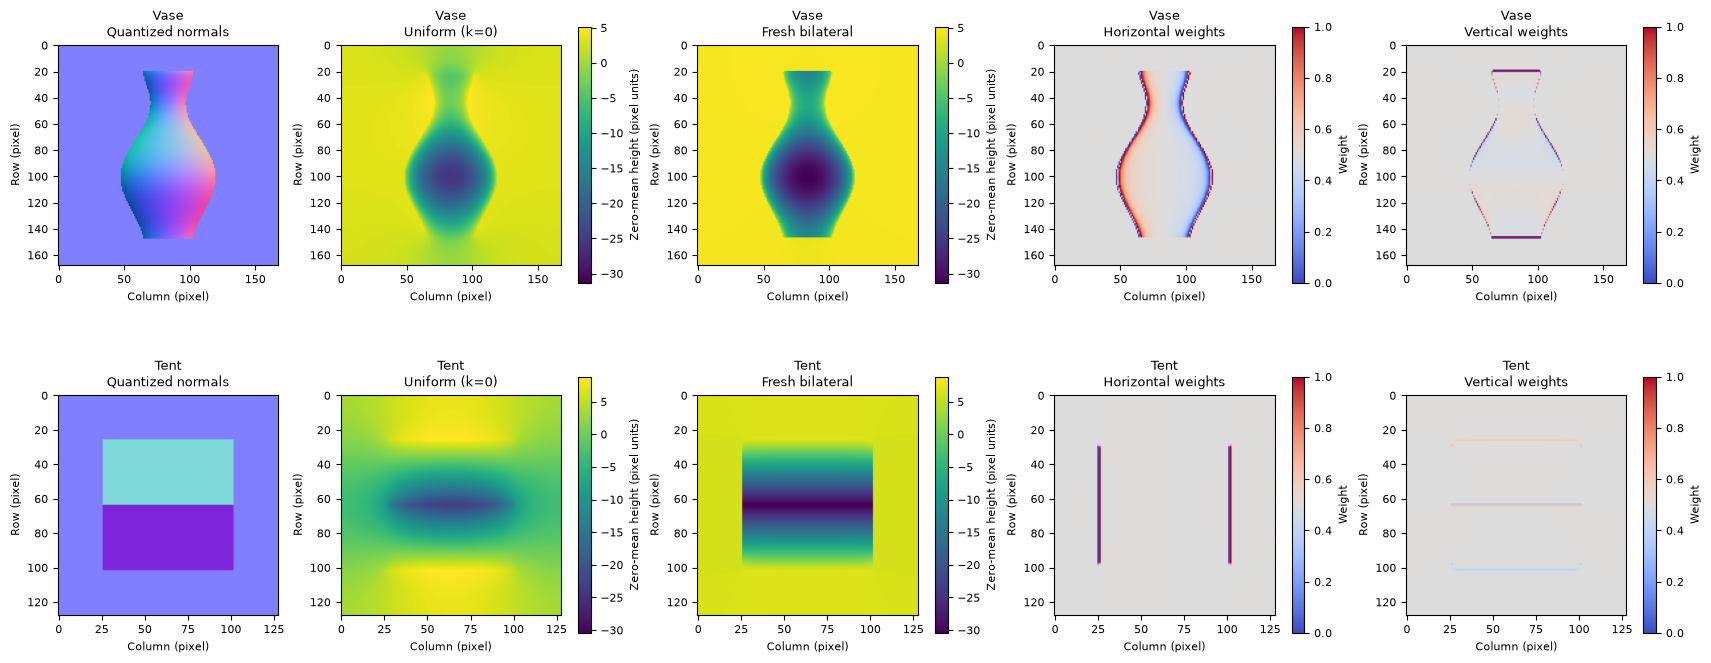

In [4]:
display(plots['field_comparison'])
plt.close(plots['field_comparison'])

### Surfaces Profiles

Actual integrated surfaces and center-row profiles. Uniform integration tends to bridge the step boundary. The original bilateral profile is identified separately from the fresh local result. Heights are not metric-distance ground truth.


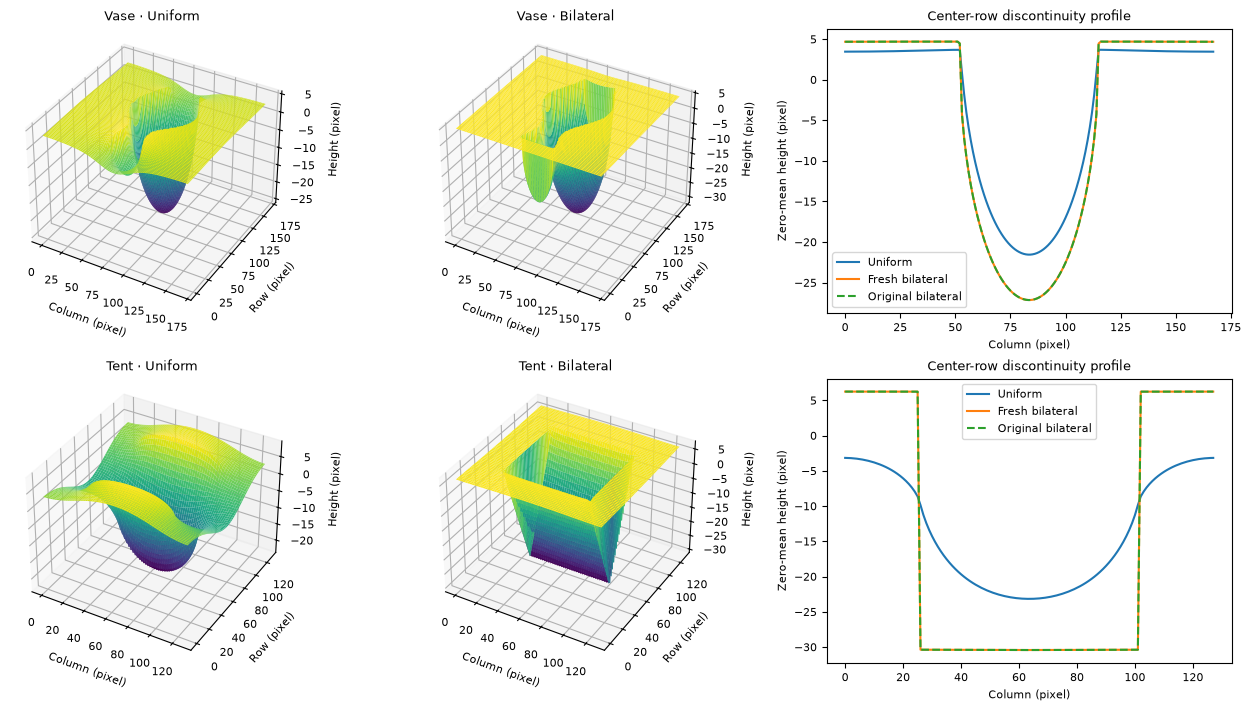

In [5]:
display(plots['surfaces_profiles'])
plt.close(plots['surfaces_profiles'])

### Numerics Physics

Original/fresh energies, signed parity errors centered at zero, and every directional constraint including the source boundary terms. Nonzero constraint residual is expected from quantization, boundaries and discontinuities.


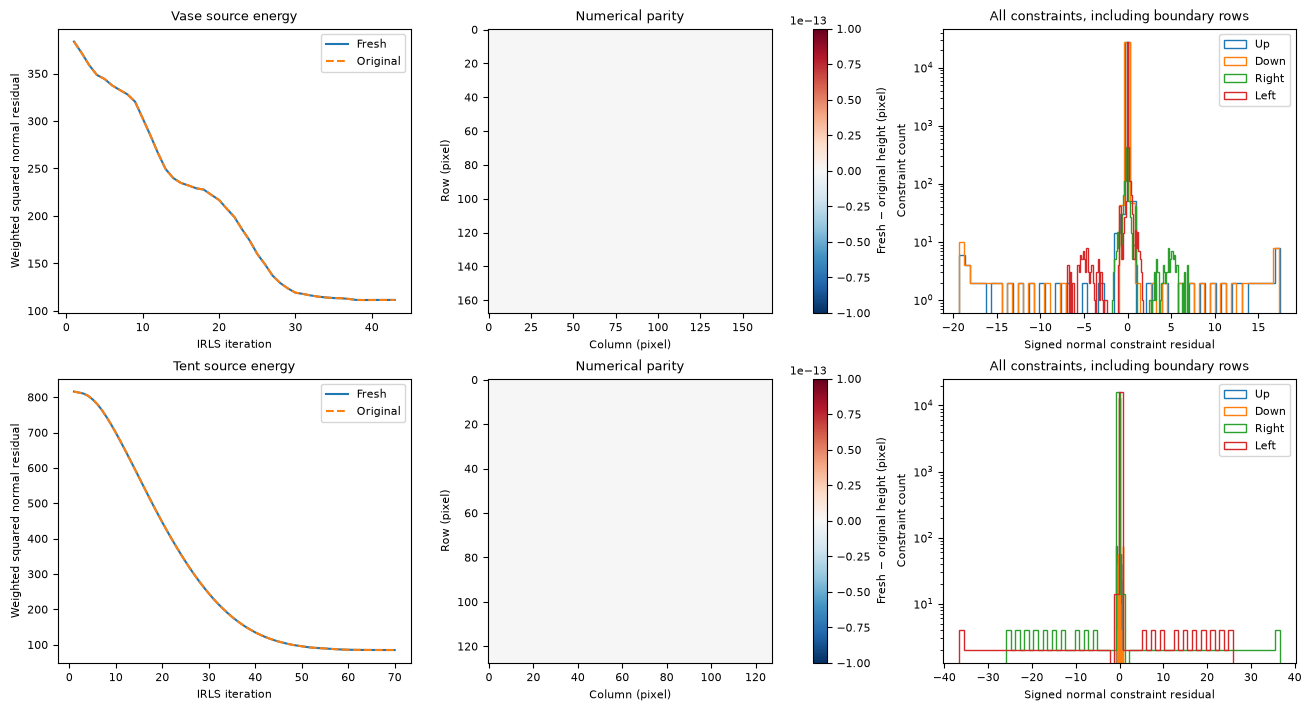

In [6]:
display(plots['numerics_physics'])
plt.close(plots['numerics_physics'])

### Sensitivity

All plotted variants were executed above. NRMSE means method-result deviation, not true-depth error. Weight-dependent residual energies are not a common physical truth metric across sharpness values.


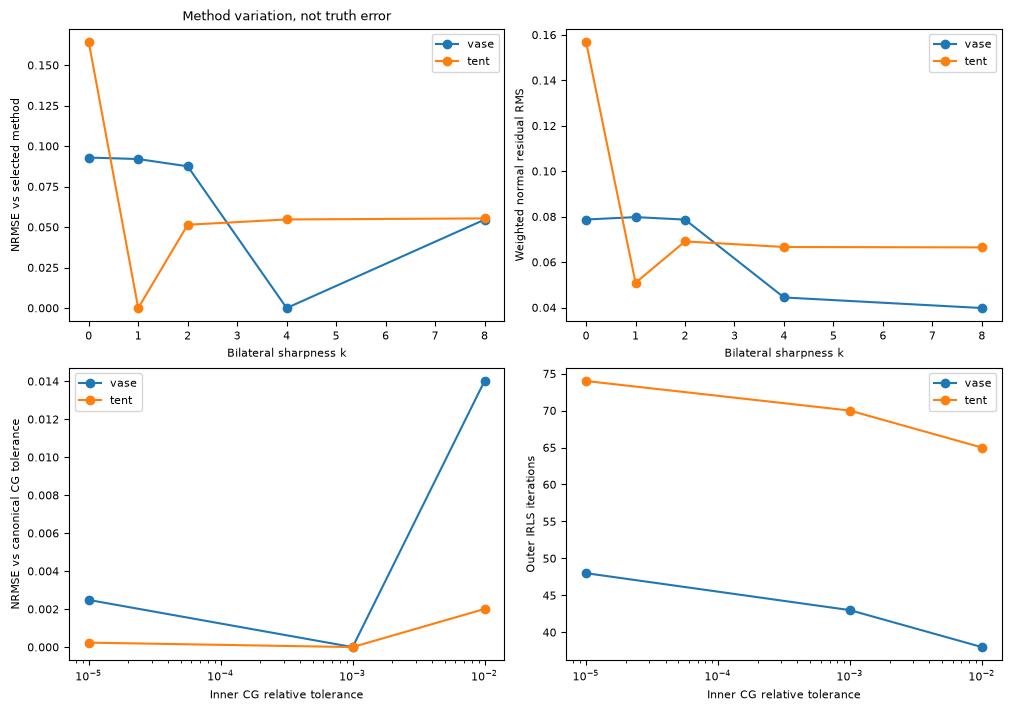

In [7]:
display(plots['sensitivity'])
plt.close(plots['sensitivity'])

## 6. Conclusion

### Interpretation and limitations

Read the actual residual, profile and sensitivity comparisons together. A discontinuity-preserving surface can agree with the original method while its absolute height, metric scale and analytic surface truth remain unknown. Quantized normals need not be exactly integrable, and a nonconvex reweighting scheme can depend on sharpness and initialization. These examples establish a reproducible method benchmark; they do not demonstrate real-camera accuracy or reproduce the paper's entire comparative study.
